# Data Wrangling Exercise: Cleaning a Messy Compound-Screening Dataset

**Scenario.** A screening lab measured physicochemical properties and assay conditions for ~1,500 small
molecules and recorded whether each compound was *active* in a biochemical assay. The data were collected by
several people over ten months, exported from different instruments and typed into a shared spreadsheet.
You now want to train a model that predicts `active` from the measured properties — but first the data
need to be cleaned.

**Learning goals**
1. Explore an unknown dataset (EDA) and *find* the problems before fixing them
2. Standardise column names and categorical labels
3. Handle missing-value codes, numbers stored as text, and censored values (`<LOD`)
4. Convert units (°C / K / °F and µM / mM / mg/mL)
5. Create boolean **flag columns** instead of silently deleting information
6. Detect and treat outliers and duplicates
7. Measure what all of this does to a **Random Forest** classifier

**Time:** about 2–3 hours. Work through the parts in order; each part ends with a checkpoint cell (`assert`s)
that tells you whether you are on track.

**Raw columns**

| Raw column | Meaning |
|---|---|
| `Compound ID` | identifier of the compound |
| `MW (g/mol)`, `LogP`, `tPSA [A^2]`, `H-Bond Donors` | physicochemical properties |
| `Assay pH`, `Temp` + `Temp_unit` | assay conditions |
| `Solubility` + `Solubilty unit` | measured solubility |
| `Method`, `operator `, `PLATE`, `Measurement Date`, `Project` | metadata |
| `Notes` | free text from the operator |
| `Active?` | **target**: was the compound active in the assay? |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold, cross_val_score

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

raw = pd.read_csv("compound_screening_raw.csv")   # never modify `raw` - always work on a copy

## Part 1 – First look (EDA)

Before cleaning anything, find out what is wrong. Work through the cells and **write down every problem you
find** (a list in a markdown cell is fine). There are at least 10 distinct problems in this dataset.

In [3]:
print(raw.shape)
print(raw.info())
raw.sample(10, random_state=1)

(1635, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1635 entries, 0 to 1634
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Compound ID       1635 non-null   str    
 1   MW (g/mol)        1604 non-null   str    
 2   LogP              1596 non-null   str    
 3   tPSA [A^2]        1589 non-null   str    
 4   H-Bond Donors     1593 non-null   str    
 5   Assay pH          1614 non-null   str    
 6   Temp              1635 non-null   float64
 7   Temp_unit         1635 non-null   str    
 8   Solubility        1593 non-null   str    
 9   Solubilty unit    1635 non-null   str    
 10  Method            1614 non-null   str    
 11  operator          1635 non-null   str    
 12  PLATE             1635 non-null   int64  
 13  Measurement Date  1635 non-null   str    
 14  Project           1635 non-null   str    
 15  Notes             419 non-null    str    
 16  Active?           1635 non-null   str    


,Compound ID,MW (g/mol),LogP,tPSA [A^2],H-Bond Donors,Assay pH,Temp,Temp_unit,Solubility,Solubilty unit,Method,operator,PLATE,Measurement Date,Project,Notes,Active?
1276,CPD-0018,278.5,4.31,106.5,1.0,7.4,310.26,kelvin,0.0453,mg/mL,AlphaScreen,Ben Meier,1,21.03.2024,PRJ-042,NaN,yes
1285,CPD-0471,389.6 g/mol,2.26,40.1,1.0,6.5,24.47,C,-999,mM,TRFRET,David Huber,2,15.06.2024,PRJ-042,repeat measurement,no
995,CPD-1246,365.8,4.11,75.1,0.0,6.5,36.62,C,42.5,uM,Fluorescence Polarization,Chiara Rossi,18,2024-03-01,PRJ-042,NaN,ACTIVE
264,CPD-0200,346.1,2.86,70.9,3.0,8.0,24.60,°C,79.3,µM,TR-FRET,David Huber,6,2024-10-12,PRJ-042,fresh DMSO stock,1
1426,CPD-1433,286.2 g/mol,4.13,-999,1.0,8.0,36.88,C,55.7,uM,alpha screen,Anna Keller,5,13.07.2024,PRJ-042,Sample precipitated,1
462,CPD-0737,426.1,NaN,70.7,3.0,7.4,25.01,C,20.9,uM,Alphascreen,david huber,17,2024-09-02,PRJ-042,fresh DMSO stock,0
75,CPD-1162,329.1,1.69,50.6,0.0,7.4,30.17,°C,83.5,µM,Alphascreen,ANNA KELLER,16,22.04.2024,PRJ-042,NaN,ACTIVE
366,CPD-0278,n.a.,2.87,20.1,0.0,7.4,37.04,C,0.0151,mg/mL,Fluorescence Polarization,chiara rossi,10,2024-01-25,PRJ-042,repeat measurement,1
1030,CPD-1217,206.1,2.75,120.4,3.0,6.5,98.40,F,0.012,mg/mL,TR-FRET,David Huber,10,17.08.2024,PRJ-042,NaN,Inactive
1044,CPD-0505,150.0,0.77,100.8,2.0,7.4,37.05,C,143.0,µM,fp,Chiara Rossi,7,"October 03, 2024",PRJ-042,NaN,no


In [4]:
for col in ["MW (g/mol)", "LogP", "tPSA [A^2]", "H-Bond Donors", "Assay pH", "Solubility"]:
    failed = raw[col][pd.to_numeric(raw[col], errors="coerce").isna()]
    print(f"{col:15s}", failed.value_counts(dropna=False).head(8).to_dict())

MW (g/mol)      {nan: 31, 'n.a.': 7, '234.2 g/mol': 3, '-': 3, '348.9 g/mol': 2, '309.5 g/mol': 2, '341.0 g/mol': 2, '282.5 g/mol': 2}
LogP            {nan: 39, 'n.a.': 12, '-': 6}
tPSA [A^2]      {nan: 46, 'n.a.': 14, '-': 8}
H-Bond Donors   {nan: 42, '-': 6, 'n.a.': 3}
Assay pH        {nan: 21, '-': 5, 'n.a.': 3}
Solubility      {nan: 42, '<LOD': 37, 'n.a.': 13, '-': 2}


In [5]:
for col in ["Method", "operator ", "Active?", "Temp_unit", "Solubilty unit"]:
    print(raw[col].value_counts(dropna=False).to_dict(), "\n")

{'FP ': 221, 'fp': 198, 'Fluorescence Polarization': 193, 'FP': 180, 'TR-FRET ': 139, 'tr-fret': 117, 'Alphascreen': 115, 'AlphaScreen': 114, 'TR-FRET': 110, 'TRFRET': 108, 'alpha screen': 99, nan: 21, 'n.a.': 9, '-999': 8, '-': 3} 

{'Ben Meier': 323, 'Anna Keller': 302, 'David Huber': 301, 'Chiara Rossi': 285, 'chiara rossi': 45, 'ben meier': 40, 'DAVID HUBER': 40, 'anna keller': 37, 'BEN MEIER': 36, 'CHIARA ROSSI': 34, 'ANNA KELLER': 34, 'david huber': 33, ' Anna Keller': 31, ' Ben Meier': 30, ' Chiara Rossi': 21, ' David Huber': 18, ' chiara rossi': 5, ' anna keller': 4, ' DAVID HUBER': 3, ' BEN MEIER': 3, ' ANNA KELLER': 3, ' ben meier': 3, ' CHIARA ROSSI': 2, ' david huber': 2} 

{'inactive': 204, 'Inactive': 193, 'no': 183, '1': 169, 'INACTIVE': 168, '0': 160, 'yes': 152, 'ACTIVE': 145, 'Active': 135, 'active': 126} 

{'C': 743, '°C': 347, 'kelvin': 125, '°F': 119, 'K': 117, 'c': 98, 'F': 86} 

{'mM': 437, 'uM': 404, 'mg/mL': 393, 'µM': 315, 'UM': 86} 



In [6]:
display(raw.describe(include="all").T)
print("exact duplicate rows:", raw.duplicated().sum())
print("duplicated compound IDs:", raw["Compound ID"].duplicated().sum())
print("unique values in Project:", raw["Project"].unique())
print("Notes that are not empty:\n", raw["Notes"].value_counts().to_dict())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Compound ID,1635,1500,CPD-0424,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MW (g/mol),1604,1216,150.0,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LogP,1596,530,n.a.,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tPSA [A^2],1589,880,-999,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
H-Bond Donors,1593,10,1.0,460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Assay pH,1614,7,7.4,717,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp,1635.0,NaN,NaN,NaN,75.721028,96.13394,19.14,24.96,30.42,76.155,310.76
Temp_unit,1635,7,C,743,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Solubility,1593,1074,<LOD,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Solubilty unit,1635,5,mM,437,NaN,NaN,NaN,NaN,NaN,NaN,NaN


exact duplicate rows: 60
duplicated compound IDs: 135
unique values in Project: <ArrowStringArray>
['PRJ-042']
Length: 1, dtype: str
Notes that are not empty:
 {'repeat measurement': 110, 'fresh DMSO stock': 40, 'see ELN p.34': 38, 'ok': 38, 're-run on new plate': 38, 'CONTAMINATION?': 37, 'hemolysed': 32, 'Sample precipitated': 31, 'pipetting error': 29, 'contaminated sample': 26}


### Solution: problems built into the data
1. Column names with spaces, units, brackets, mixed case, trailing whitespace, a typo (`Solubilty unit`)
2. Numbers stored as text: `"402.0 g/mol"`; at least six different missing-value codes (`NA`, `n.a.`, `-`, `N/A`, empty, `-999`)
3. `<LOD` (below limit of detection) in the solubility column – censored values, not missing at random
4. Temperature in °C, K **and** °F, with several spellings of the unit (`C`, `°C`, `c`, `K`, `kelvin`, `F`, `°F`)
5. Solubility in µM, mM **and** mg/mL (spellings `uM`, `µM`, `UM`) – mg/mL needs the molecular weight to convert
6. Inconsistent categories: `FP`/`fp`/`Fluorescence Polarization`, operator names in different case and with spaces, target as `Active`/`1`/`yes`/…
7. Dates in three formats (ISO, `dd.mm.yyyy`, `Month dd, yyyy`) – `dayfirst=True` / `format="mixed"` silently swaps day and month of the ISO dates
8. Impossible values (MW = 0 or 35,000; logP = 99.9; negative tPSA)
9. Exact duplicate rows **and** re-measurements of the same compound ID with slightly different values
10. Free-text notes (`contaminated`, `precipitated`, `pipetting error`, `hemolysed`) that mark unreliable rows – for those rows ~70 % of the labels are random
11. A constant column (`Project`) and an ID column that must not be used as a feature

## Part 2 – Standardise column names

Target format: `snake_case`, lowercase, no units, no spaces/brackets/special characters, no typos.
Do it **programmatically** (string methods / regex on `df.columns`), not by retyping 17 names by hand –
then fix the remaining special cases with `rename`.

Final names we want: `compound_id, mw, logp, tpsa, hbd, ph, temp_value, temp_unit, solubility, solubility_unit,
method, operator, plate, measurement_date, project, notes, is_active`

In [7]:
df = raw.copy()

df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"\(.*?\)|\[.*?\]", "", regex=True)   # drop units in () and []
              .str.strip()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)       # spaces, '-', '?' -> '_'
              .str.strip("_"))

df = df.rename(columns={"h_bond_donors": "hbd", "assay_ph": "ph", "temp": "temp_value",
                        "solubilty_unit": "solubility_unit", "active": "is_active"})
df.columns.tolist()

['compound_id',
 'mw',
 'logp',
 'tpsa',
 'hbd',
 'ph',
 'temp_value',
 'temp_unit',
 'solubility',
 'solubility_unit',
 'method',
 'operator',
 'plate',
 'measurement_date',
 'project',
 'notes',
 'is_active']

In [8]:
# ---- Checkpoint 2 ----
expected = ["compound_id", "mw", "logp", "tpsa", "hbd", "ph", "temp_value", "temp_unit", "solubility",
            "solubility_unit", "method", "operator", "plate", "measurement_date", "project", "notes", "is_active"]
assert df.columns.tolist() == expected, f"Column names differ:\n{df.columns.tolist()}"
print("Part 2 OK")

Part 2 OK


## Part 3 – Missing values, numbers stored as text, censored values

1. Strip leading/trailing whitespace in all text columns.
2. Replace all missing-value codes (`NA`, `n.a.`, `N/A`, `-`, empty string, `-999`) by real `NaN`.
   *Think:* why is `-999` dangerous if you forget it?
3. `mw` contains entries like `"402.0 g/mol"` – extract the number.
4. Entries `<LOD` in `solubility` mean "below the limit of detection". Create a **boolean flag column**
   `is_below_lod` (True for these rows) **before** converting the column to numbers – the information
   "below LOD" is real information, and we do not want to lose it just because we turn the value into NaN.
5. Convert `mw, logp, tpsa, hbd, ph, solubility` to float.

Remove the `project` column (constant, no information) at the end of this part.

In [9]:
# 1) strip whitespace in all text columns
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip()

# 2) unify missing-value codes
df = df.replace(["NA", "n.a.", "N/A", "-", "", "-999"], np.nan)

# 3) "402.0 g/mol" -> 402.0
df["mw"] = df["mw"].str.replace("g/mol", "", regex=False)

# 4) flag censored values BEFORE converting to numbers
df["is_below_lod"] = df["solubility"].eq("<LOD")

# 5) numeric conversion
for c in ["mw", "logp", "tpsa", "hbd", "ph", "solubility"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.drop(columns=["project"])
df.dtypes

compound_id             str
mw                  float64
logp                float64
tpsa                float64
hbd                 float64
ph                  float64
temp_value          float64
temp_unit               str
solubility          float64
solubility_unit         str
method                  str
operator                str
plate                 int64
measurement_date        str
notes                   str
is_active               str
is_below_lod           bool
dtype: object

In [10]:
# ---- Checkpoint 3 ----
for c in ["mw", "logp", "tpsa", "hbd", "ph", "solubility"]:
    assert pd.api.types.is_float_dtype(df[c]) or pd.api.types.is_integer_dtype(df[c]), f"{c} is not numeric"
assert "project" not in df.columns
assert df["is_below_lod"].dtype == bool and 20 <= df["is_below_lod"].sum() <= 55
assert (df[["mw", "logp", "tpsa", "hbd", "ph"]] == -999).sum().sum() == 0
print("Part 3 OK")

Part 3 OK


## Part 4 – Categorical columns and dates

* `method` → exactly three categories: `FP`, `TR-FRET`, `AlphaScreen`
* `operator` → title case, no stray spaces (four people)
* `is_active` → integer 0/1 (`active`, `Active`, `1`, `yes`, … → 1)
* `measurement_date` → real `datetime`. The dates come in three formats (`2024-03-05`, `05.03.2024`,
  `March 05, 2024`); the dotted ones are day-first (European). Dates are a classic trap: a wrong format
  guess does not raise an error, it silently gives you wrong dates. All measurements were taken between
  2024-01-08 and 2024-11-02 – use this to check your result!

In [11]:
df["method"] = (df["method"].str.lower().str.replace(r"[^a-z]", "", regex=True)
                .map({"fp": "FP", "fluorescencepolarization": "FP",
                      "trfret": "TR-FRET", "alphascreen": "AlphaScreen"}))

df["operator"] = df["operator"].str.title()

df["is_active"] = df["is_active"].str.lower().isin(["active", "1", "yes"]).astype(int)

# Parse each format separately. (Beware: dayfirst=True would silently flip day and month of the ISO dates!)
d_raw = df["measurement_date"]
parsed = pd.to_datetime(d_raw, format="%Y-%m-%d", errors="coerce")
parsed = parsed.fillna(pd.to_datetime(d_raw, format="%d.%m.%Y", errors="coerce"))
parsed = parsed.fillna(pd.to_datetime(d_raw, format="%B %d, %Y", errors="coerce"))
df["measurement_date"] = parsed

print(df["method"].value_counts(dropna=False).to_dict())
print(df["operator"].value_counts().to_dict())
print(df["measurement_date"].min(), df["measurement_date"].max())

{'FP': 792, 'TR-FRET': 474, 'AlphaScreen': 328, nan: 41}
{'Ben Meier': 435, 'Anna Keller': 411, 'David Huber': 397, 'Chiara Rossi': 392}
2024-01-08 00:00:00 2024-11-02 00:00:00


In [12]:
# ---- Checkpoint 4 ----
assert set(df["method"].dropna().unique()) == {"FP", "TR-FRET", "AlphaScreen"}
assert df["operator"].nunique() == 4
assert set(df["is_active"].unique()) == {0, 1}
assert pd.api.types.is_datetime64_any_dtype(df["measurement_date"])
assert df["measurement_date"].notna().all(), "Some dates could not be parsed"
assert df["measurement_date"].min() >= pd.Timestamp("2024-01-08") and df["measurement_date"].max() <= pd.Timestamp("2024-11-02"),     "Some dates were parsed wrongly (day/month swapped?)"
print("Part 4 OK")

Part 4 OK


## Part 5 – Unit conversion

Create two harmonised columns:

* `temp_c` – temperature in **°C**   (K → °C: subtract 273.15; °F → °C: (F − 32) · 5/9)
* `solubility_um` – solubility in **µM**
  * mM → µM: × 1000
  * mg/mL → µM: needs the molecular weight!   µM = (mg/mL) / MW[g/mol] · 10⁶   (check this on paper!)

First normalise the unit strings (`°`, `µ`, upper/lower case, `kelvin`), then use `np.select` or `.map`.
**Careful:** a few `mw` values are physically impossible (you will flag them properly in Part 6). Make sure such
values do not contaminate the mg/mL → µM conversion – otherwise you create new garbage from old garbage.

Afterwards drop the old value/unit columns. Does the result look physically plausible?
(Assay temperatures in this lab are between roughly 20 and 38 °C.)

In [13]:
t = df["temp_unit"].str.lower().str.replace("°", "", regex=False)
df["temp_c"] = np.select([t.isin(["k", "kelvin"]), t == "f"],
                         [df["temp_value"] - 273.15, (df["temp_value"] - 32) * 5 / 9],
                         default=df["temp_value"])

u = df["solubility_unit"].str.lower().str.replace("µ", "u", regex=False)
mw_ok = df["mw"].where(df["mw"].between(50, 1500))   # impossible MW values must not enter the conversion
df["solubility_um"] = np.select([u == "um", u == "mm", u == "mg/ml"],
                                [df["solubility"], df["solubility"] * 1000, df["solubility"] / mw_ok * 1e6],
                                default=np.nan)

df = df.drop(columns=["temp_value", "temp_unit", "solubility", "solubility_unit"])
df[["temp_c", "solubility_um"]].describe()

,temp_c,solubility_um
count,1635.000000,1517.000000
mean,28.434752,145.341723
std,6.179973,196.035375
min,19.140000,1.780000
25%,24.780000,37.909559
50%,25.190000,81.046422
75%,36.750000,175.000000
max,37.780000,2600.000000


In [14]:
# ---- Checkpoint 5 ----
assert df["temp_c"].between(15, 40).all(), "Temperature conversion looks wrong"
assert df["solubility_um"].dropna().between(0.01, 1e5).all(), "Solubility conversion looks wrong"
print("Part 5 OK")

Part 5 OK


## Part 6 – Flags: quality issues, duplicates, outliers

Instead of deleting rows immediately, first add **boolean flag columns**. This keeps your decisions
transparent and reversible – you can compare "with" and "without" later (Part 8).

1. `qc_issue` – True if the free-text `notes` indicate an unreliable measurement
   (*contaminat…, precipitat…, pipetting error, hemoly…*; careful: spelling and capitalisation vary).
   Notes such as "repeat measurement" or "ok" are **not** quality issues.
2. `is_duplicate` – True for every repeated entry of a `compound_id` except the first one.
   (`df.duplicated(subset=...)`. Why is `df.duplicated()` without `subset` not enough?)
3. `is_outlier` – True if `mw`, `logp` or `tpsa` is outside a **physically sensible range**
   (suggestion: MW 50–1500, logP −5…10, tPSA 1–250). Set the impossible values themselves to `NaN`,
   because they are measurement errors, not real compounds.
4. `has_missing_feature` – True if any of the model features (`mw, logp, tpsa, hbd, ph, temp_c, solubility_um`)
   is missing *at this point* (after step 3).

**Discussion:** `solubility_um` has a long right tail. Would you flag the large values as outliers using the
IQR rule? Try it on the raw and on the log scale and decide. (Hint: solubility is roughly log-normal.)

In [15]:
FEATURES = ["mw", "logp", "tpsa", "hbd", "ph", "temp_c", "solubility_um"]

df["qc_issue"] = df["notes"].fillna("").str.contains("contamin|precipitat|pipetting|hemoly", case=False)

df["is_duplicate"] = df.duplicated(subset="compound_id", keep="first")

limits = {"mw": (50, 1500), "logp": (-5, 10), "tpsa": (1, 250)}
df["is_outlier"] = False
for col, (lo, hi) in limits.items():
    bad = (df[col] < lo) | (df[col] > hi)
    df["is_outlier"] |= bad
    df.loc[bad, col] = np.nan

df["has_missing_feature"] = df[FEATURES].isna().any(axis=1)

df[["qc_issue", "is_duplicate", "is_outlier", "is_below_lod", "has_missing_feature"]].sum()

qc_issue               155
is_duplicate           135
is_outlier              32
is_below_lod            37
has_missing_feature    385
dtype: int64

In [16]:
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

print("IQR outliers, raw scale:", iqr_flags(df["solubility_um"]).sum())
print("IQR outliers, log scale:", iqr_flags(np.log10(df["solubility_um"])).sum())
# On the raw scale many perfectly valid compounds are flagged simply because the distribution is skewed.

IQR outliers, raw scale: 127
IQR outliers, log scale: 10


In [17]:
# ---- Checkpoint 6 ----
for c in ["qc_issue", "is_duplicate", "is_outlier", "has_missing_feature"]:
    assert df[c].dtype == bool, f"{c} must be boolean"
assert 120 <= df["qc_issue"].sum() <= 190
assert 110 <= df["is_duplicate"].sum() <= 160
assert 15 <= df["is_outlier"].sum() <= 50
assert df["mw"].dropna().between(50, 1500).all() and df["tpsa"].dropna().between(1, 250).all()
print("Part 6 OK")

Part 6 OK


## Part 7 – Before / after: what did the cleaning change?

The two cells below are **given**. Run them and answer the questions underneath.

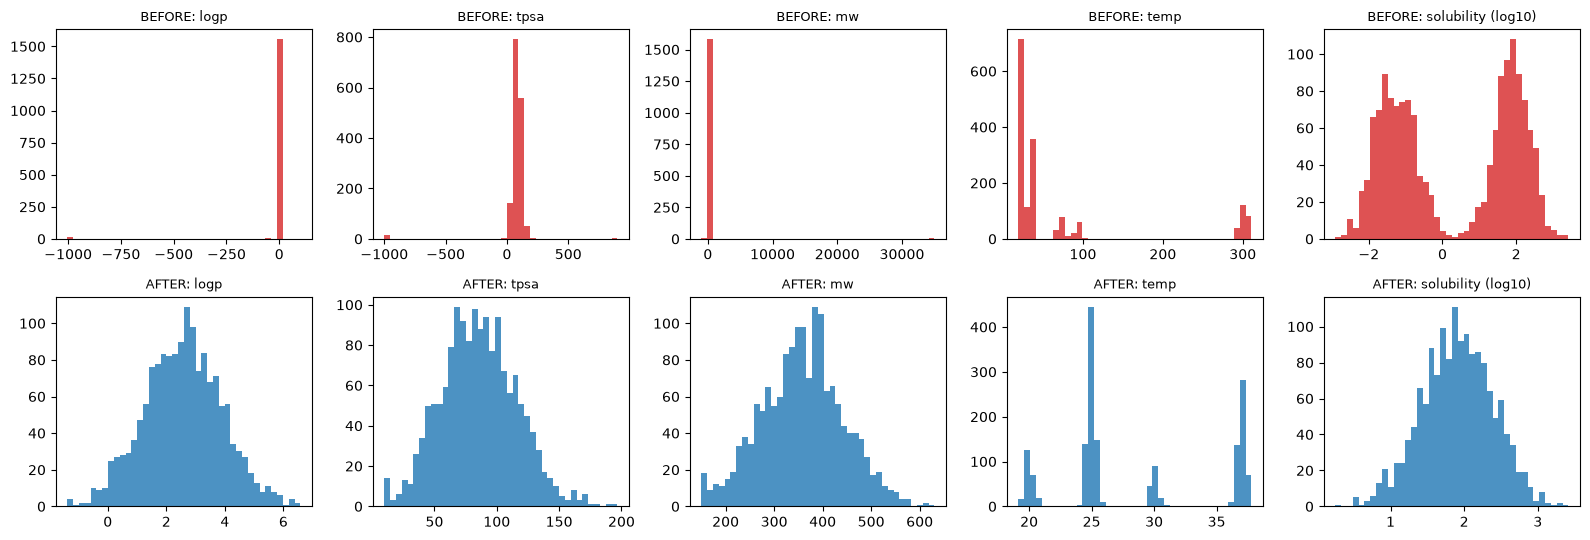

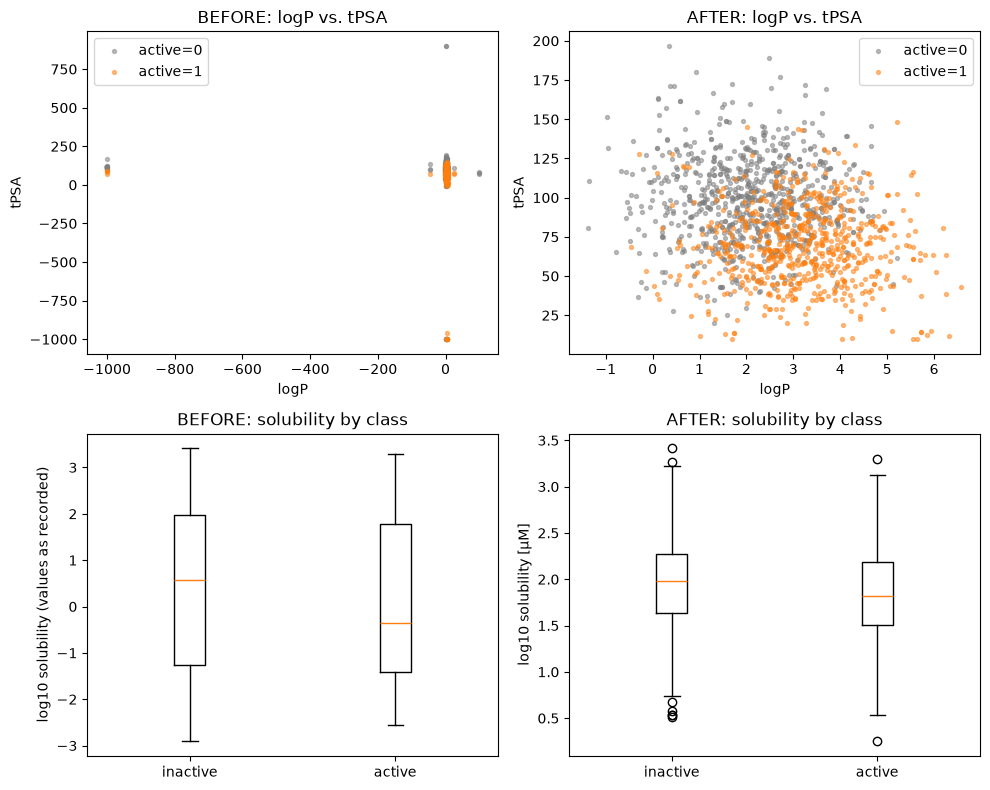

In [18]:
def plot_distributions(before, after, cols=("logp", "tpsa", "mw", "temp", "solubility")):
    fig, axes = plt.subplots(2, len(cols), figsize=(3.2 * len(cols), 5.5))
    for j, c in enumerate(cols):
        for i, (d, name, colr) in enumerate([(before, "BEFORE", "tab:red"), (after, "AFTER", "tab:blue")]):
            x = d[c].dropna()
            if c == "solubility":
                x = np.log10(x[x > 0])
            axes[i, j].hist(x, bins=40, color=colr, alpha=0.8)
            axes[i, j].set_title(f"{name}: {c}" + (" (log10)" if c == "solubility" else ""), fontsize=9)
    plt.tight_layout(); plt.show()


def plot_patterns(before, after):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for k, (d, name) in enumerate([(before, "BEFORE"), (after, "AFTER")]):
        ax = axes[0, k]
        for lab, colr in [(0, "tab:grey"), (1, "tab:orange")]:
            s = d[d["active"] == lab]
            ax.scatter(s["logp"], s["tpsa"], s=8, alpha=0.5, c=colr, label=f"active={lab}")
        ax.set_xlabel("logP"); ax.set_ylabel("tPSA"); ax.set_title(f"{name}: logP vs. tPSA"); ax.legend()
        ax = axes[1, k]
        sol = d["solubility"].where(d["solubility"] > 0)
        data = [np.log10(sol[d["active"] == lab].dropna()) for lab in (0, 1)]
        ax.boxplot(data, tick_labels=["inactive", "active"])
        ax.set_ylabel("log10 solubility (values as recorded)" if k == 0 else "log10 solubility [µM]")
        ax.set_title(f"{name}: solubility by class")
    plt.tight_layout(); plt.show()


before = pd.DataFrame({
    "logp": pd.to_numeric(raw["LogP"], errors="coerce"),
    "tpsa": pd.to_numeric(raw["tPSA [A^2]"], errors="coerce"),
    "mw": pd.to_numeric(raw["MW (g/mol)"].astype(str).str.replace("g/mol", "", regex=False), errors="coerce"),
    "temp": raw["Temp"],
    "solubility": pd.to_numeric(raw["Solubility"], errors="coerce"),
    "active": raw["Active?"].astype(str).str.strip().str.lower().isin(["active", "1", "yes"]).astype(int),
})
after = df.rename(columns={"temp_c": "temp", "solubility_um": "solubility", "is_active": "active"})

plot_distributions(before, after)
plot_patterns(before, after)

**Questions**

1. Which axes changed the most between BEFORE and AFTER? Which single problem caused this?
2. In the logP-vs-tPSA scatter plot: what pattern separates active from inactive compounds, and why was it
   hard to see before?
3. In the solubility boxplot: why do active and inactive compounds look identical BEFORE, and different AFTER?
4. The temperature histogram BEFORE shows several clusters. Which values belong to which unit?
5. Is a value of `logP = 6.5` an outlier that should be removed? How did we decide the limits in Part 6?

### Solution – expected observations
1. `logp`, `tpsa`, `mw`: glitch values (99.9, 900, 35,000) squash the axes so the real distribution is a thin spike. Temperature: three clusters (≈20–37 °C, ≈290–310 K, ≈70–100 °F).
2. After cleaning, actives sit at higher logP / lower tPSA; before, the outliers stretch the axes and the structure is invisible.
3. Solubility values in µM, mM and mg/mL are on three different scales; mixing them erases the (real) relationship between solubility and activity.
4. K cluster ≈ 293–310, °F cluster ≈ 68–100, °C cluster ≈ 20–38.
5. No – it is a plausible compound. The limits are *domain knowledge* (physically impossible / far outside drug-like space), not a statistical rule.

## Part 8 – Does the cleaning improve a Random Forest?

**Task:** predict `is_active` from the measured properties.

The helper below evaluates a Random Forest with 5-fold cross-validation, repeated 3 times. It reports the
mean accuracy in two ways:

* **random CV** – rows are split randomly (what most people do by default)
* **grouped CV** – all rows of the same compound end up in the same fold, so a compound is never in the
  training *and* the test set

Missing values are imputed (median) *inside* the pipeline, i.e. separately in each training fold.

In [19]:
def evaluate(X, y, groups, n_estimators=200, repeats=3):
    """Returns (accuracy with random CV, accuracy with grouped CV), each as mean over folds and repeats."""
    model = make_pipeline(SimpleImputer(strategy="median"),
                          RandomForestClassifier(n_estimators, random_state=0, n_jobs=-1))
    rnd = cross_val_score(model, X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=0))
    grp = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
        grp.append(cross_val_score(model, X, y, cv=cv, groups=groups).mean())
    return rnd.mean(), float(np.mean(grp))

### 8.1 Baseline: the 'quick and dirty' pipeline on the raw data

In [20]:
# Quick-and-dirty: drop ID/notes/date, convert whatever can be converted, one-hot encode the rest
X_raw = raw.drop(columns=["Compound ID", "Notes", "Measurement Date", "Project", "Active?"]).copy()
for c in X_raw.columns:
    conv = pd.to_numeric(X_raw[c], errors="coerce")
    if conv.notna().mean() > 0.5:
        X_raw[c] = conv
X_raw = pd.get_dummies(X_raw)
y_raw = raw["Active?"].astype(str).str.strip().str.lower().isin(["active", "1", "yes"]).astype(int)

acc_raw = evaluate(X_raw, y_raw, groups=raw["Compound ID"])
print(f"RAW data   ->  {X_raw.shape[1]} features | random CV: {acc_raw[0]:.3f} | grouped CV: {acc_raw[1]:.3f}")

RAW data   ->  58 features | random CV: 0.818 | grouped CV: 0.789


**Before you continue:** how many features did `get_dummies` create from the raw data and why?
Which features did the Random Forest "see" for temperature and solubility?

### 8.2 Your cleaned data – three scenarios

Build the feature matrix from `df`: the seven numeric `FEATURES` plus the one-hot encoded `method`
(`pd.get_dummies(df["method"], dtype=float)`). Then evaluate three versions of the training data:

* **A** – cleaned columns and units, but keep duplicates and QC-flagged rows
* **B** – A, but remove duplicates (`is_duplicate`)
* **C** – B, but also remove rows with a QC issue (`qc_issue`)

Define each scenario as a boolean row mask (this is exactly what the flag columns are for!).

In [21]:
X_all = pd.concat([df[FEATURES], pd.get_dummies(df["method"], dtype=float)], axis=1)
y_all = df["is_active"]

masks = {
    "A: cleaned, keep duplicates + QC rows": pd.Series(True, index=df.index),
    "B: A without duplicates": ~df["is_duplicate"],
    "C: B without QC-flagged rows": ~df["is_duplicate"] & ~df["qc_issue"],
}

results = {"RAW (quick and dirty)": acc_raw}
for name, m in masks.items():
    results[name] = evaluate(X_all[m], y_all[m], groups=df.loc[m, "compound_id"])

res = pd.DataFrame(results, index=["random CV", "grouped CV"]).T.round(3)
res

,random CV,grouped CV
RAW (quick and dirty),0.818,0.789
"A: cleaned, keep duplicates + QC rows",0.841,0.814
B: A without duplicates,0.820,0.816
C: B without QC-flagged rows,0.835,0.841


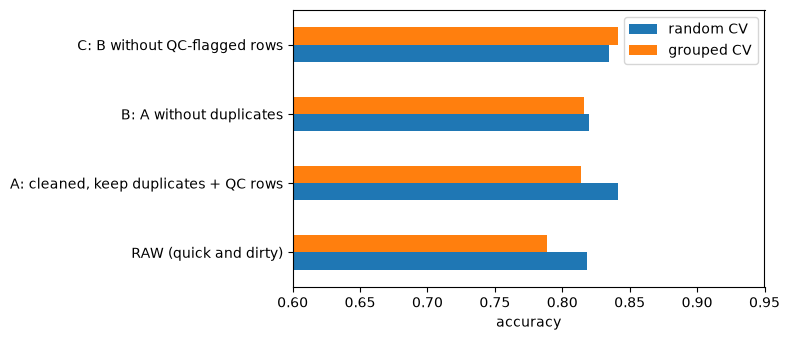

In [22]:
res.plot.barh(figsize=(8, 3.5)); plt.xlim(0.6, 0.95); plt.xlabel("accuracy"); plt.tight_layout(); plt.show()

**Questions**

1. Compare RAW and B in the *grouped CV* column. How many accuracy points did the cleaning of units, glitches and
   categories buy you?
2. Compare A and B in the *random CV* column: the accuracy goes **down** when duplicates are removed. Is B worse?
   Which of the two numbers can you trust, and why? (Hint: what happens when a compound appears in the training
   *and* the test fold?)
3. What does removing the QC-flagged rows (C) improve, and what is the price? Would you also remove such rows from
   the *test* set in a real project?
4. Re-run the notebook after changing the outlier limits in Part 6 (e.g. logP −1…7). What happens?

### 8.3 Feature importance before vs. after

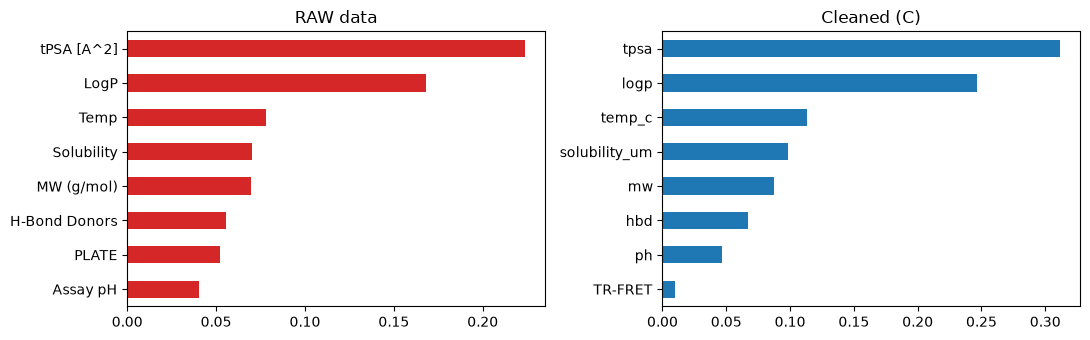

In [23]:
def top_importances(X, y, k=8):
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns)
    rf = RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(X, y)
    return pd.Series(rf.feature_importances_, index=X.columns).nlargest(k)

mC = masks["C: B without QC-flagged rows"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
top_importances(X_raw, y_raw).sort_values().plot.barh(ax=axes[0], color="tab:red", title="RAW data")
top_importances(X_all[mC], y_all[mC]).sort_values().plot.barh(ax=axes[1], color="tab:blue", title="Cleaned (C)")
plt.tight_layout(); plt.show()

**Questions:** Which features does the model rely on in the raw data (hint: look at `Temp`, `Solubility`, `PLATE`)?
Are the same features important after cleaning? Is a high importance for `PLATE` or the compound ID a good sign?

## Part 9 – Bonus challenges

1. **Impute vs. drop.** Compare dropping all rows with missing features to median imputation, and to
   imputation + the `has_missing_feature` flag as an additional feature.
2. **Flags as features.** Add `is_below_lod` as a feature. Does it help? Why might "below LOD" be informative?
3. **Re-measurements.** Instead of keeping only the first entry per compound, average the numeric columns of
   repeated measurements (`groupby("compound_id")`). Does the accuracy change?
4. **Pipeline.** Turn Parts 2–6 into one function `clean(raw) -> df` and test it on a second dataset:
   `python generate_messy_data.py 7` writes a new file with a different random seed. Does your function
   still work without changes? (What did you hard-code?)
5. **Honest evaluation.** Hold out 20 % of the compounds *before* any cleaning decision that uses the labels
   (e.g. QC removal) and report the final accuracy only once on this untouched test set.

### Solution – typical results (seed 42, accuracy ± a few points depending on CV split)

| Scenario | random CV | grouped CV |
|---|---|---|
| RAW (quick and dirty) | ≈ 0.82 | ≈ 0.79 |
| A: cleaned, keep duplicates + QC rows | ≈ 0.84 | ≈ 0.81 |
| B: without duplicates | ≈ 0.82 | ≈ 0.82 |
| C: without QC-flagged rows | ≈ 0.84 | ≈ 0.84 |

Take-aways to discuss:
* Unit harmonisation, glitch removal and category clean-up give a modest but consistent gain of ~3 points
  (grouped CV, RAW → B). Random Forests are fairly robust to *scale* problems, but not to *mixed* units of the same
  quantity (e.g. solubility in µM, mM and mg/mL, or temperature in °C and K).
* **Leakage:** with duplicates in the data, random CV is too optimistic (A: 0.84 random vs. 0.81 grouped; RAW: 0.82 vs. 0.79).
  After removing the duplicates the two estimates agree (B). The "drop" from A to B in random CV is the honest result.
* Removing unreliable rows (C) gives another ~2–3 points, but costs ~10 % of the data. The flag columns make this a
  conscious, reversible decision instead of a silent `dropna()`.
* Each student can use a different seed (`python generate_messy_data.py <seed>`) to avoid copying; the numbers vary
  by roughly ±2 points between seeds, so always discuss *tendencies*, not exact values.